# Credit Card Fraud Detection Under Extreme Class Imbalance

## Phase 1: Data Understanding and Exploratory Data Analysis

Goal: Understand the dataset, class imbalance, data quality, and feature behavior before training any model.    

In [2]:
import pandas as pd

data_path = "../data/raw/creditcard.csv"
df = pd.read_csv(data_path)

df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.shape

(284807, 31)

In [4]:
df.columns.tolist()

['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount',
 'Class']

In [5]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [6]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

### Type of class ---> Class 0 == Normal and Class 1 == fraud
#### Class = 0
#### Class = 1

### Understandig data type for all the features
- **Time float64 numerical /continuous**
- **V1 - V28 --> float64 --> numerical/ continuous transformed features**

- **Amount --> float64 --> numerica/ continuous**
- **Class --> int64 binary --> categorical target**

### We need to check these things 
- Null
- duplicates
- extreme values
- class imbalance
- unusual distributions
- possible leakage issues

### Checkig for Null values
There is no Misisng vlaue (Null) beacsue this data has  been already cleaned up 

In [14]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(1081)

### We found 1081 duplicat data here 
**we need to inspect these dat firts to know wether  to remove it or keep it**
Specially i will check the ** time stamp ** to know the dat are really duplicate or not  becasue  it is not possible to send  the same amonut within  a same time , so the time will be most reliable factor for us to ubderstand the dats is duplicate or not 

In [18]:
df[df.duplicated(keep=False)].head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


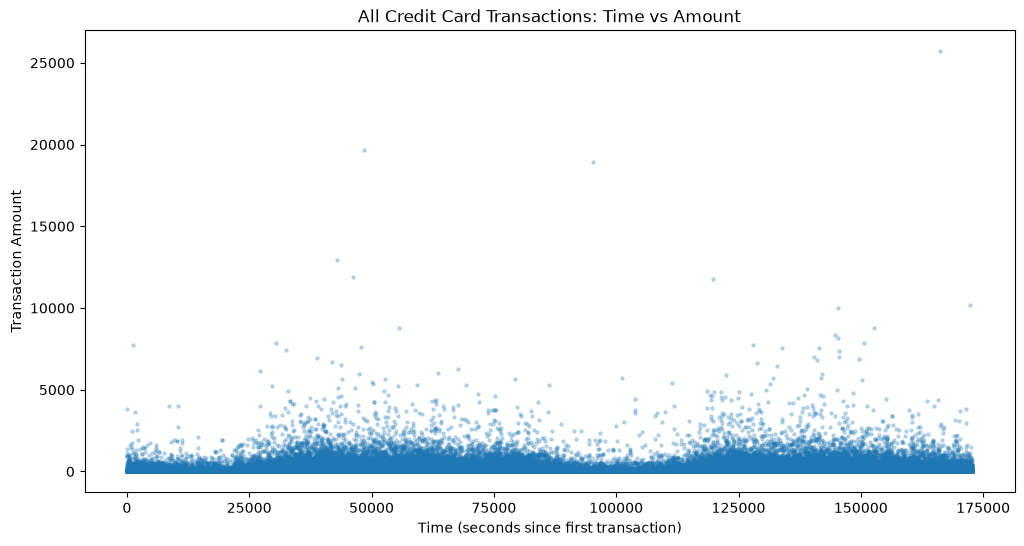

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.scatter(
    df["Time"],
    df["Amount"],
    s=5,
    alpha=0.25
)

plt.xlabel("Time (seconds since first transaction)")
plt.ylabel("Transaction Amount")
plt.title("All Credit Card Transactions: Time vs Amount")

plt.show()

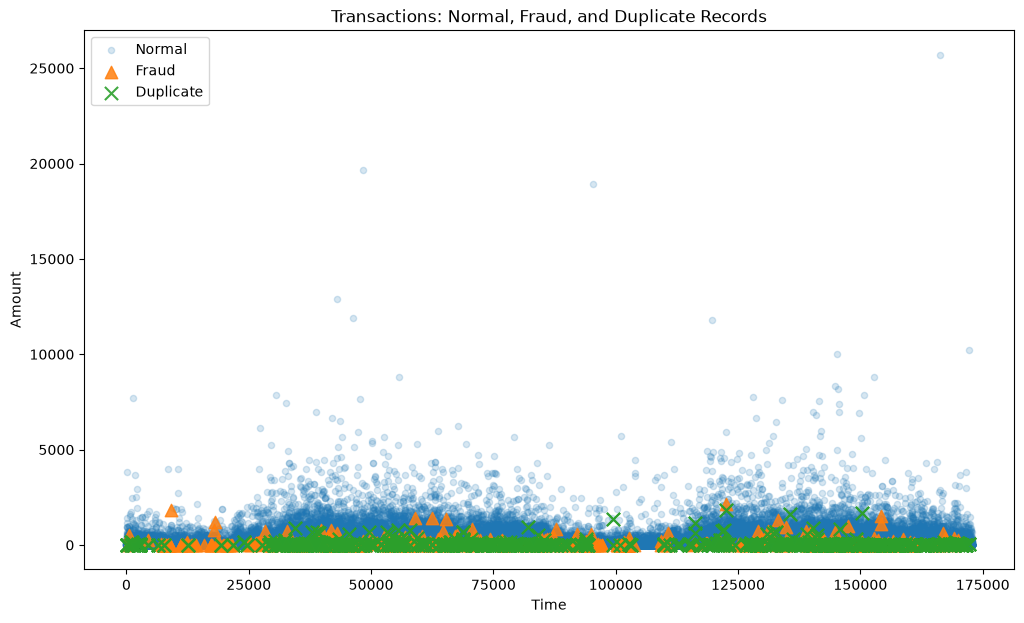

In [21]:
import matplotlib.pyplot as plt

duplicate_mask = df.duplicated(keep=False)

normal = df[(df["Class"] == 0) & (~duplicate_mask)]
fraud = df[(df["Class"] == 1) & (~duplicate_mask)]
duplicates = df[duplicate_mask]

plt.figure(figsize=(12, 7))

plt.scatter(
    normal["Time"],
    normal["Amount"],
    s=20,
    alpha=0.18,
    label="Normal"
)

plt.scatter(
    fraud["Time"],
    fraud["Amount"],
    s=80,
    marker="^",
    alpha=0.85,
    label="Fraud"
)

plt.scatter(
    duplicates["Time"],
    duplicates["Amount"],
    s=90,
    marker="x",
    alpha=0.9,
    label="Duplicate"
)

plt.xlabel("Time")
plt.ylabel("Amount")
plt.title("Transactions: Normal, Fraud, and Duplicate Records")
plt.legend()

plt.show()

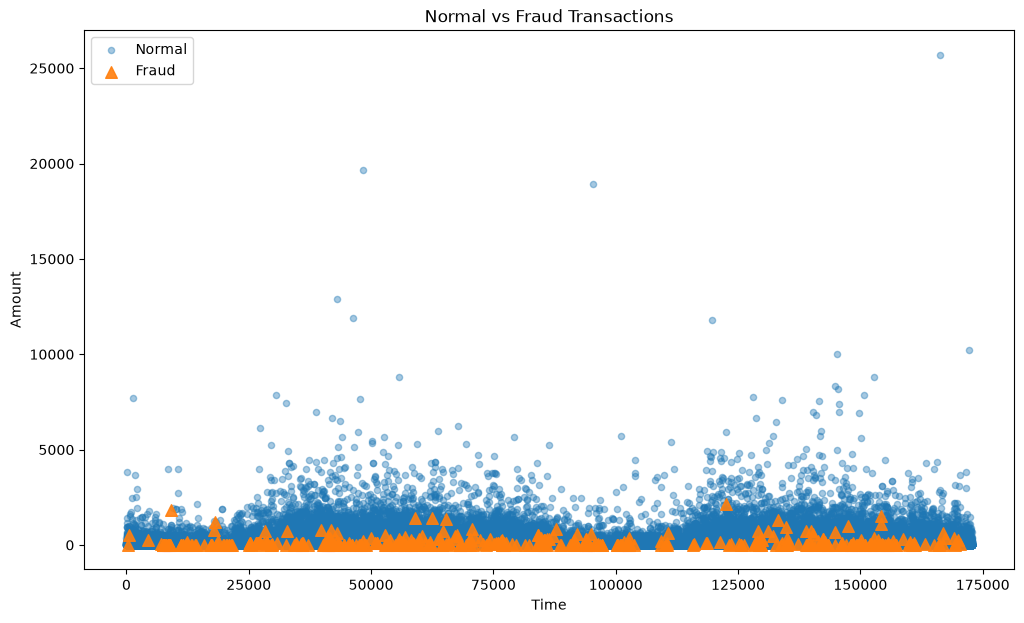

In [26]:
import matplotlib.pyplot as plt

normal = df[df["Class"] == 0]
fraud = df[df["Class"] == 1]

plt.figure(figsize=(12, 7))

plt.scatter(
    normal["Time"],
    normal["Amount"],
    s=20,
    marker="o",
    alpha=0.4,
    label="Normal"
)

plt.scatter(
    fraud["Time"],
    fraud["Amount"],
    s=70,
    marker="^",
    alpha=0.9,
    label="Fraud"
)

plt.xlabel("Time")
plt.ylabel("Amount")
plt.title("Normal vs Fraud Transactions")
plt.legend()

plt.show()

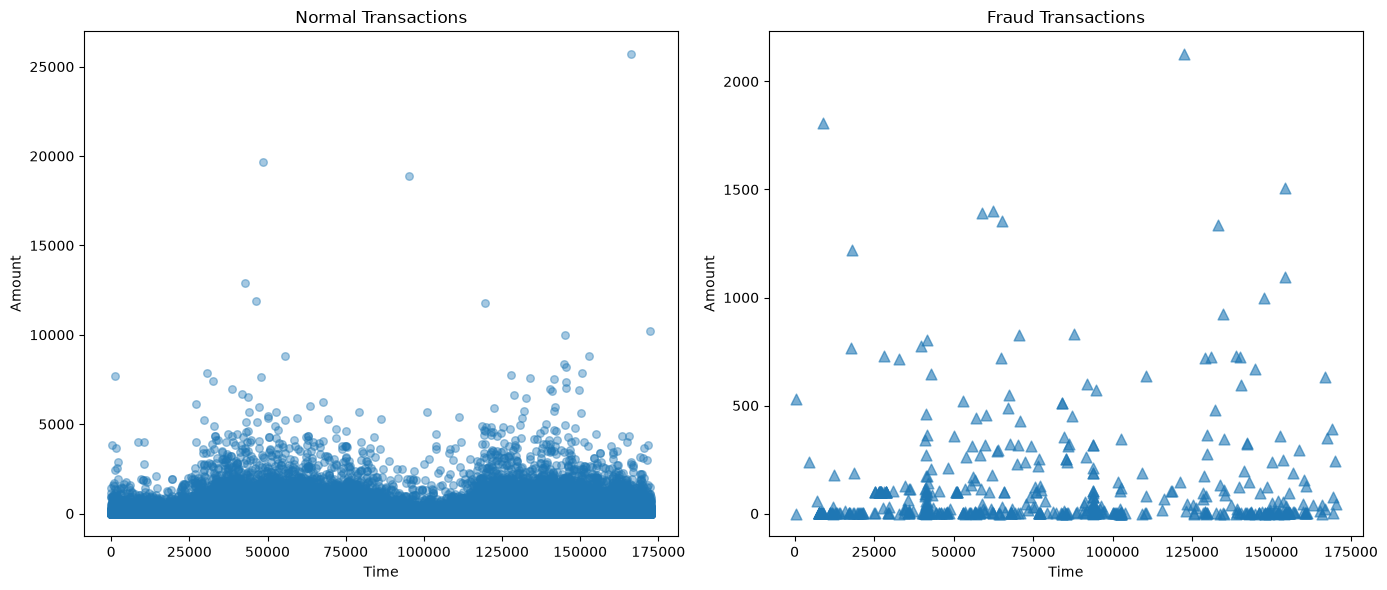

In [32]:
import matplotlib.pyplot as plt

normal = df[df["Class"] == 0]
fraud = df[df["Class"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Normal transactions
axes[0].scatter(
    normal["Time"],
    normal["Amount"],
    s=30,
    marker="o",
    alpha=0.4
)

axes[0].set_title("Normal Transactions")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Amount")


# Fraud transactions
axes[1].scatter(
    fraud["Time"],
    fraud["Amount"],
    s=60,
    marker="^",
    alpha=0.6
)

axes[1].set_title("Fraud Transactions")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Amount")

plt.tight_layout()
plt.show()

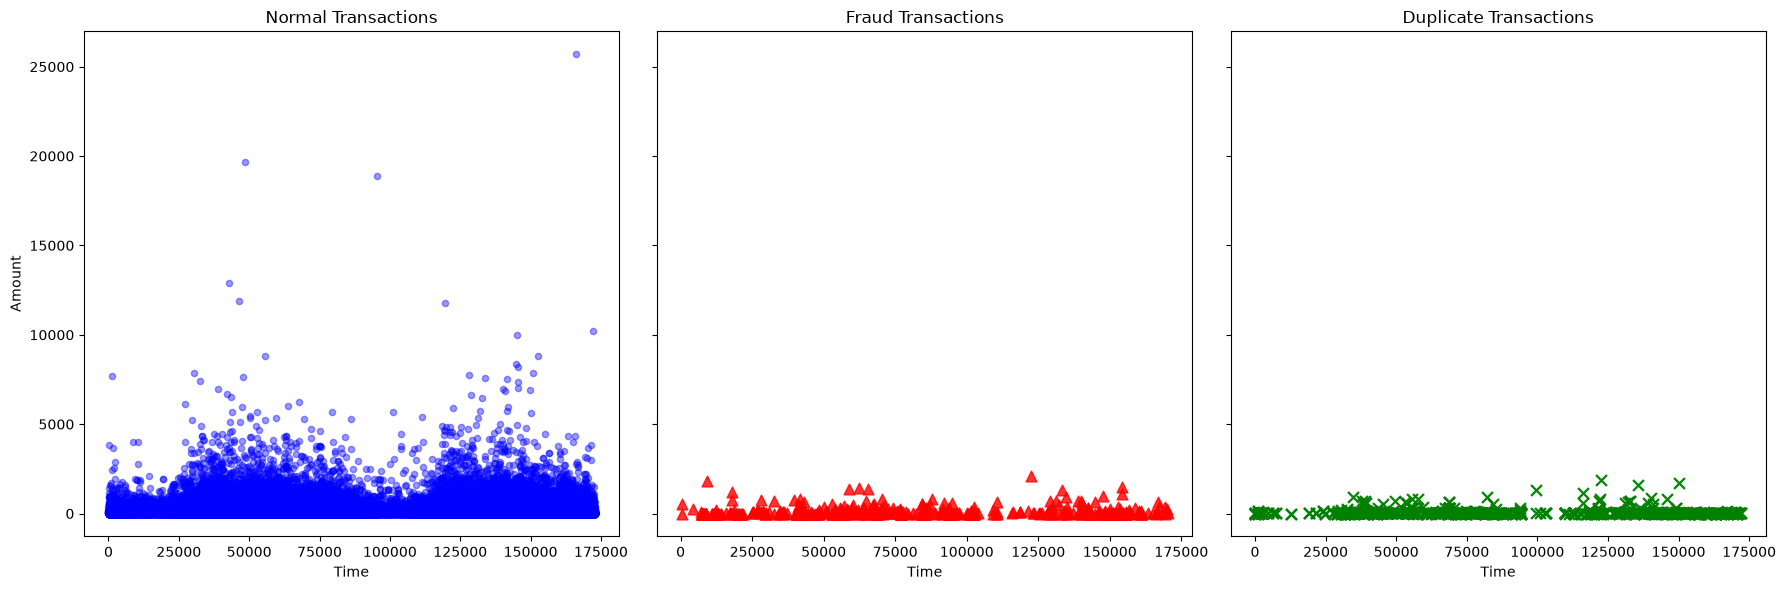

In [35]:
import matplotlib.pyplot as plt

# Separate groups
normal = df[df["Class"] == 0]
fraud = df[df["Class"] == 1]

duplicate_mask = df.duplicated(keep=False)
duplicates = df[duplicate_mask]

# Create 3 side-by-side plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# 1. Normal transactions - blue circles
axes[0].scatter(
    normal["Time"],
    normal["Amount"],
    s=20,
    marker="o",
    color="blue",
    alpha=0.4
)

axes[0].set_title("Normal Transactions")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Amount")


# 2. Fraud transactions - red triangles
axes[1].scatter(
    fraud["Time"],
    fraud["Amount"],
    s=60,
    marker="^",
    color="red",
    alpha=0.8
)

axes[1].set_title("Fraud Transactions")
axes[1].set_xlabel("Time")


# 3. Duplicate transactions - green X
axes[2].scatter(
    duplicates["Time"],
    duplicates["Amount"],
    s=60,
    marker="x",
    color="green",
    alpha=0.8
)

axes[2].set_title("Duplicate Transactions")
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [36]:
print("hello")

hello
